# Population Overview

**Research question:** How does genetic variation differ between human populations?

We compare three populations from three continents:
- **YRI** — Yoruba, Nigeria (African ancestry)
- **CEU** — Utah residents (European ancestry)
- **CHB** — Han Chinese, Beijing (East Asian ancestry)

This section loads the 1000 Genomes sample metadata and confirms sample sizes 
for our chosen populations before any variant-level analysis.

In [1]:
import pandas as pd

# Load the population metadata
# sep='\s+' means "split on whitespace" since the file is space/tab separated
panel = pd.read_csv(
    "../data/raw/1000_genomes/integrated_call_samples_v3.20130502.ALL.panel.txt",
    sep=r"\s+"
)

panel.head()

,sample,pop,super_pop,gender
0,HG00096,GBR,EUR,male
1,HG00097,GBR,EUR,female
2,HG00099,GBR,EUR,female
3,HG00100,GBR,EUR,female
4,HG00101,GBR,EUR,male


What this does: isin(...) keeps only rows where the pop column matches one of our 3 chosen codes. .value_counts() then counts how many rows (samples) exist per population — this should match what we saw earlier (YRI=108, CEU=99, CHB=103).

In [2]:
# Filter to just our 3 chosen populations
populations_of_interest = ["YRI", "CEU", "CHB"]
subset = panel[panel["pop"].isin(populations_of_interest)]

# Count samples per population
counts = subset["pop"].value_counts()
print(counts)

pop
YRI    108
CHB    103
CEU     99
Name: count, dtype: int64


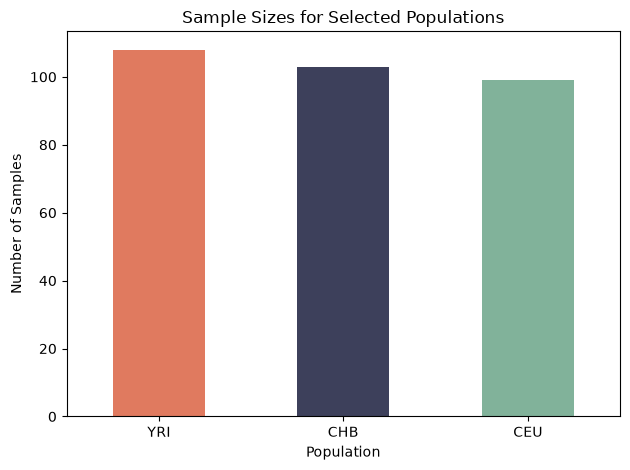

In [3]:
import matplotlib.pyplot as plt

counts.plot(kind="bar", color=["#e07a5f", "#3d405b", "#81b29a"])
plt.title("Sample Sizes for Selected Populations")
plt.xlabel("Population")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../results/sample_sizes.png", dpi=150)
plt.show()